# Culinary Communities: Ingredient Networks and the Language of Cooking
**02805 Social Graphs and Interactions — Final Project**

**Research question**: Does an ingredient's structural position in the culinary co-occurrence network predict recipe success — and do the communities found in the network have distinct linguistic fingerprints in how cooks write about them?

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import ast
import random
import re
from collections import Counter, defaultdict
from itertools import combinations
from scipy import stats

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
matplotlib.rcParams['font.size'] = 10
matplotlib.rcParams['axes.spines.top'] = False
matplotlib.rcParams['axes.spines.right'] = False

from sklearn.feature_extraction.text import TfidfVectorizer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import community as community_louvain

np.random.seed(42)
random.seed(42)

DATA = 'food_com_recipes/'
print('Setup complete')

Setup complete


## 1. Load and clean data

In [2]:
# Load recipes
recipes = pd.read_csv(DATA + 'RAW_recipes.csv')
print(f'Recipes: {len(recipes):,}')

# Parse ingredients from string representation of list
recipes['ingr_list'] = recipes['ingredients'].apply(ast.literal_eval)

# Load interactions, drop 0-ratings (these are unrated placeholders in Food.com)
interactions = pd.read_csv(DATA + 'RAW_interactions.csv')
interactions = interactions[interactions['rating'] > 0].copy()
print(f'Interactions (rating > 0): {len(interactions):,}')
print(f'Rating distribution:\n{interactions["rating"].value_counts().sort_index()}')

Recipes: 231,637
Interactions (rating > 0): 1,071,520
Rating distribution:
1     12818
2     14123
3     40855
4    187360
5    816364
Name: rating, dtype: int64


In [3]:
# Compute mean rating per recipe
recipe_ratings = (
    interactions
    .groupby('recipe_id')
    .agg(mean_rating=('rating', 'mean'), n_reviews=('rating', 'count'))
    .reset_index()
)

# Merge ratings onto recipes; keep only recipes with >= 3 reviews for stability
recipes = recipes.merge(recipe_ratings, left_on='id', right_on='recipe_id', how='inner')
recipes = recipes[recipes['n_reviews'] >= 3].copy()
print(f'Recipes with ≥3 reviews: {len(recipes):,}')
print(f'Mean rating overall: {recipes["mean_rating"].mean():.3f}')

Recipes with ≥3 reviews: 90,437
Mean rating overall: 4.659


In [4]:
# Identify top-500 ingredients by frequency across all recipes
all_ingr = []
for ingr_list in recipes['ingr_list']:
    all_ingr.extend(ingr_list)
ingr_freq = Counter(all_ingr)

TOP_K = 500
top_ingr = set(ing for ing, _ in ingr_freq.most_common(TOP_K))
print(f'Top-{TOP_K} ingredients cover {sum(ingr_freq[i] for i in top_ingr)/sum(ingr_freq.values()):.1%} of all ingredient mentions')

# Filter each recipe's ingredients to the top-K set
recipes['ingr_filtered'] = recipes['ingr_list'].apply(lambda lst: [i for i in lst if i in top_ingr])

# Keep only recipes that have >= 2 filtered ingredients (need pairs for edges)
recipes = recipes[recipes['ingr_filtered'].apply(len) >= 2].copy()
print(f'Recipes with ≥2 top-K ingredients: {len(recipes):,}')

Top-500 ingredients cover 78.8% of all ingredient mentions
Recipes with ≥2 top-K ingredients: 87,313


## 2. Build the ingredient co-occurrence network

In [5]:
# Nodes: top-500 ingredients
# Edges: two ingredients are connected if they appear in the same recipe
# Edge weight: number of recipes they co-occur in

edge_counts = Counter()
for ingr_list in recipes['ingr_filtered']:
    for a, b in combinations(sorted(ingr_list), 2):
        edge_counts[(a, b)] += 1

print(f'Total potential edges: {len(edge_counts):,}')

# Apply backbone threshold: keep edges with weight >= 5 to remove noise
EDGE_THRESHOLD = 5
G = nx.Graph()
G.add_nodes_from(top_ingr)
for (a, b), w in edge_counts.items():
    if w >= EDGE_THRESHOLD:
        G.add_edge(a, b, weight=w)

# Keep only the largest connected component
lcc = max(nx.connected_components(G), key=len)
G = G.subgraph(lcc).copy()

print(f'Network (threshold={EDGE_THRESHOLD}): {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')
print(f'Density: {nx.density(G):.4f}')
print(f'Average degree: {sum(d for _,d in G.degree())/G.number_of_nodes():.1f}')

Total potential edges: 87,468
Network (threshold=5): 500 nodes, 47331 edges
Density: 0.3794
Average degree: 189.3


## 3. Network analysis: degree distribution, centrality

In [6]:
# Degree distribution
degrees = [d for _, d in G.degree()]
print(f'Degree: min={min(degrees)}, max={max(degrees)}, mean={np.mean(degrees):.1f}, median={np.median(degrees):.0f}')

# Top ingredients by (weighted) degree
weighted_degree = dict(G.degree(weight='weight'))
top_by_degree = sorted(weighted_degree.items(), key=lambda x: x[1], reverse=True)[:20]
print('\nTop 10 ingredients by weighted degree:')
for ingr, wd in top_by_degree[:10]:
    print(f'  {ingr}: {wd:,}')

Degree: min=30, max=499, mean=189.3, median=154

Top 10 ingredients by weighted degree:
  salt: 270,755
  butter: 155,787
  onion: 124,877
  sugar: 122,446
  eggs: 97,181
  olive oil: 95,638
  water: 95,243
  flour: 86,900
  garlic cloves: 80,594
  milk: 73,062


In [7]:
# Betweenness centrality (sample-based for speed)
print('Computing betweenness centrality (k=200 sample)...')
betweenness = nx.betweenness_centrality(G, k=200, weight='weight', normalized=True)

print('Top 10 by betweenness:')
for ingr, bc in sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f'  {ingr}: {bc:.4f}')

Computing betweenness centrality (k=200 sample)...
Top 10 by betweenness:
  canola oil: 0.0092
  boiling water: 0.0082
  hot water: 0.0079
  cooking spray: 0.0074
  lemon: 0.0068
  ground ginger: 0.0067
  cream: 0.0062
  cornstarch: 0.0060
  ground nutmeg: 0.0060
  half-and-half: 0.0060


## 4. Community detection (Louvain) + null model validation

In [8]:
# Louvain community detection
partition = community_louvain.best_partition(G, weight='weight', random_state=42)
modularity_obs = community_louvain.modularity(partition, G, weight='weight')

community_sizes = Counter(partition.values())
n_communities = len(community_sizes)
print(f'Communities found: {n_communities}')
print(f'Modularity Q (observed): {modularity_obs:.4f}')
print(f'Community sizes: {sorted(community_sizes.values(), reverse=True)}')

Communities found: 3
Modularity Q (observed): 0.2149
Community sizes: [323, 153, 24]


In [9]:
# Null model: shuffle edge weights 100 times, recompute modularity
# This checks whether community structure is stronger than expected by chance
print('Running null model (100 shuffled networks)...')

def shuffle_weights(G):
    """Return a copy of G with edge weights randomly permuted."""
    H = G.copy()
    weights = [H[u][v]['weight'] for u, v in H.edges()]
    random.shuffle(weights)
    for (u, v), w in zip(H.edges(), weights):
        H[u][v]['weight'] = w
    return H

null_modularities = []
for _ in range(100):
    H = shuffle_weights(G)
    p = community_louvain.best_partition(H, weight='weight', random_state=None)
    null_modularities.append(community_louvain.modularity(p, H, weight='weight'))

null_mean = np.mean(null_modularities)
null_std = np.std(null_modularities)
z_score = (modularity_obs - null_mean) / null_std

print(f'Null modularity: {null_mean:.4f} ± {null_std:.4f}')
print(f'Observed: {modularity_obs:.4f}')
print(f'Z-score: {z_score:.1f} (> 2 = significant)')

Running null model (100 shuffled networks)...
Null modularity: 0.2512 ± 0.0027
Observed: 0.2149
Z-score: -13.3 (> 2 = significant)


In [10]:
# Label communities by their most characteristic ingredients
# (top 5 by frequency within each community)
community_to_nodes = defaultdict(list)
for node, comm in partition.items():
    community_to_nodes[comm].append(node)

# Manual inspection: print top nodes per community
print('Top nodes per community (sorted by weighted degree):')
comm_labels = {}
for comm_id in sorted(community_sizes, key=community_sizes.get, reverse=True):
    nodes = community_to_nodes[comm_id]
    top_nodes = sorted(nodes, key=lambda n: weighted_degree.get(n, 0), reverse=True)[:8]
    print(f'  Community {comm_id} ({len(nodes)} nodes): {top_nodes}')
    comm_labels[comm_id] = ', '.join(top_nodes[:3])

Top nodes per community (sorted by weighted degree):
  Community 2 (323 nodes): ['onion', 'olive oil', 'water', 'garlic cloves', 'pepper', 'garlic', 'parmesan cheese', 'salt and pepper']
  Community 1 (153 nodes): ['salt', 'butter', 'sugar', 'eggs', 'flour', 'milk', 'baking powder', 'brown sugar']
  Community 0 (24 nodes): ['soy sauce', 'honey', 'cornstarch', 'ginger', 'sesame oil', 'sesame seeds', 'peanut oil', 'rice vinegar']


In [11]:
# Assign human-readable labels based on inspection
# (you will update these after running the cell above)
# We automatically label by dominant ingredient for reproducibility
auto_labels = {}
label_themes = ['Baking', 'Savory/Meat', 'Vegetables', 'Asian', 'Mediterranean', 
                'Dairy/Eggs', 'Spices', 'Seafood', 'Other A', 'Other B']
for i, comm_id in enumerate(sorted(community_sizes, key=community_sizes.get, reverse=True)):
    nodes = community_to_nodes[comm_id]
    top_node = sorted(nodes, key=lambda n: weighted_degree.get(n, 0), reverse=True)[0]
    auto_labels[comm_id] = top_node.title()

print('Auto-labels (top ingredient per community):')
for comm_id, label in sorted(auto_labels.items()):
    print(f'  Comm {comm_id}: {label} ({community_sizes[comm_id]} nodes)')

Auto-labels (top ingredient per community):
  Comm 0: Soy Sauce (24 nodes)
  Comm 1: Salt (153 nodes)
  Comm 2: Onion (323 nodes)


## 5. Rating analysis: does network position predict recipe success?

In [12]:
# For each ingredient, compute its mean rating across all recipes it appears in
ingr_ratings = defaultdict(list)
for _, row in recipes.iterrows():
    for ingr in row['ingr_filtered']:
        if ingr in G.nodes():
            ingr_ratings[ingr].append(row['mean_rating'])

ingr_mean_rating = {ingr: np.mean(ratings) for ingr, ratings in ingr_ratings.items() if len(ratings) >= 20}
print(f'Ingredients with ≥20 recipe ratings: {len(ingr_mean_rating)}')

# Build a dataframe with network metrics + rating per ingredient
ingr_df = pd.DataFrame([
    {
        'ingredient': ingr,
        'degree': G.degree(ingr),
        'weighted_degree': weighted_degree.get(ingr, 0),
        'betweenness': betweenness.get(ingr, 0),
        'community': partition.get(ingr, -1),
        'mean_rating': ingr_mean_rating[ingr],
        'n_recipes': len(ingr_ratings[ingr])
    }
    for ingr in ingr_mean_rating
    if ingr in G.nodes() and ingr in partition
])

print(ingr_df.describe())

Ingredients with ≥20 recipe ratings: 500
           degree  weighted_degree  betweenness   community  mean_rating  \
count  500.000000       500.000000   500.000000  500.000000   500.000000   
mean   189.324000      9444.336000     0.001807    1.598000     4.661574   
std    109.582899     20309.726908     0.001361    0.580577     0.050237   
min     30.000000       451.000000     0.000000    0.000000     4.446006   
25%    104.000000      1896.250000     0.000862    1.000000     4.631196   
50%    153.500000      3540.500000     0.001514    2.000000     4.662546   
75%    251.500000      7985.250000     0.002379    2.000000     4.696336   
max    499.000000    270755.000000     0.009152    2.000000     4.805884   

          n_recipes  
count    500.000000  
mean    1266.200000  
std     2654.458344  
min      209.000000  
25%      305.000000  
50%      514.500000  
75%     1054.250000  
max    34678.000000  


In [13]:
# Correlation: degree vs. mean rating
r_deg, p_deg = stats.pearsonr(ingr_df['degree'], ingr_df['mean_rating'])
r_bet, p_bet = stats.pearsonr(ingr_df['betweenness'], ingr_df['mean_rating'])
print(f'Degree vs. mean rating:      r={r_deg:.3f}, p={p_deg:.3e}')
print(f'Betweenness vs. mean rating: r={r_bet:.3f}, p={p_bet:.3e}')

# Null check: shuffle ratings 1000 times
null_rs = []
ratings_arr = ingr_df['mean_rating'].values.copy()
degrees_arr = ingr_df['degree'].values
for _ in range(1000):
    shuffled = ratings_arr.copy()
    np.random.shuffle(shuffled)
    null_rs.append(stats.pearsonr(degrees_arr, shuffled)[0])

null_r_mean = np.mean(null_rs)
null_r_std = np.std(null_rs)
z_rating = (r_deg - null_r_mean) / null_r_std
print(f'\nNull (shuffled ratings): r={null_r_mean:.4f} ± {null_r_std:.4f}')
print(f'Observed r={r_deg:.3f}, z={z_rating:.1f}')

Degree vs. mean rating:      r=-0.067, p=1.360e-01
Betweenness vs. mean rating: r=0.016, p=7.243e-01

Null (shuffled ratings): r=-0.0016 ± 0.0459
Observed r=-0.067, z=-1.4


In [14]:
# Rating by community
comm_rating_data = {}
for comm_id in community_to_nodes:
    comm_ingrs = [n for n in community_to_nodes[comm_id] if n in ingr_mean_rating]
    if len(comm_ingrs) >= 3:
        # Collect all recipe ratings for recipes containing any ingredient in this community
        recipe_set = set()
        for _, row in recipes.iterrows():
            if any(i in community_to_nodes[comm_id] for i in row['ingr_filtered']):
                recipe_set.add(row['id'])
        # Get those ratings
        comm_ratings = recipes[recipes['id'].isin(recipe_set)]['mean_rating'].values
        if len(comm_ratings) >= 10:
            comm_rating_data[comm_id] = comm_ratings

print('Community rating statistics (mean ± std, n):')
for comm_id, ratings in sorted(comm_rating_data.items()):
    label = auto_labels.get(comm_id, str(comm_id))
    print(f'  Comm {comm_id} [{label}]: {np.mean(ratings):.3f} ± {np.std(ratings):.3f} (n={len(ratings):,})')

Community rating statistics (mean ± std, n):
  Comm 0 [Soy Sauce]: 4.644 ± 0.399 (n=13,456)
  Comm 1 [Salt]: 4.656 ± 0.392 (n=72,685)
  Comm 2 [Onion]: 4.657 ± 0.382 (n=70,917)


## 6. Text analysis: TF-IDF on reviews per community

In [15]:
# Join reviews to recipes
# For each community, build a corpus of all reviews for recipes in that community

# First, map recipe_id -> community (a recipe can belong to multiple communities
# if it has ingredients from several; we assign by plurality)
recipe_comm_counts = defaultdict(Counter)
for _, row in recipes.iterrows():
    recipe_id = row['id']
    for ingr in row['ingr_filtered']:
        if ingr in partition:
            recipe_comm_counts[recipe_id][partition[ingr]] += 1

# Assign each recipe to its plurality community
recipe_primary_comm = {
    rid: cnt.most_common(1)[0][0]
    for rid, cnt in recipe_comm_counts.items()
    if cnt
}

print(f'Recipes assigned to a community: {len(recipe_primary_comm):,}')
comm_recipe_counts = Counter(recipe_primary_comm.values())
print('Recipes per community:', dict(sorted(comm_recipe_counts.items())))

Recipes assigned to a community: 87,313
Recipes per community: {0: 1108, 1: 31726, 2: 54479}


In [16]:
# Join interactions (reviews) to community assignments
interactions_filtered = interactions[interactions['review'].notna() & (interactions['review'].str.len() > 20)].copy()
interactions_filtered['community'] = interactions_filtered['recipe_id'].map(recipe_primary_comm)
interactions_filtered = interactions_filtered.dropna(subset=['community'])
interactions_filtered['community'] = interactions_filtered['community'].astype(int)

print(f'Reviews with community assignment: {len(interactions_filtered):,}')
print(interactions_filtered['community'].value_counts())

Reviews with community assignment: 853,941
2    526688
1    317527
0      9726
Name: community, dtype: int64


In [17]:
# Build one document per community (concatenation of all reviews)
# Use TF-IDF to find characteristic words for each community
# (relative to all other communities — that's what TF-IDF gives us here)

# Focus on communities with enough recipes
FOCUS_COMMUNITIES = [c for c, n in comm_recipe_counts.most_common() if n >= 500][:6]
print(f'Focusing on {len(FOCUS_COMMUNITIES)} largest communities: {FOCUS_COMMUNITIES}')

# Sample up to 2000 reviews per community for speed
corpus_docs = []
corpus_comm_ids = []
for comm_id in FOCUS_COMMUNITIES:
    comm_reviews = interactions_filtered[interactions_filtered['community'] == comm_id]['review']
    sample = comm_reviews.sample(min(2000, len(comm_reviews)), random_state=42)
    # One document = concatenation of sampled reviews
    corpus_docs.append(' '.join(sample.values))
    corpus_comm_ids.append(comm_id)

print(f'Corpus: {len(corpus_docs)} community documents')

Focusing on 3 largest communities: [2, 1, 0]
Corpus: 3 community documents


In [19]:
# TF-IDF
vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=5000,
    min_df=1,
    ngram_range=(1, 2),
    token_pattern=r'\b[a-z][a-z]+\b'
)
# .toarray() converts to dense immediately — avoids scipy 1D sparse slice error
tfidf_matrix = vectorizer.fit_transform(corpus_docs).toarray()
feature_names = vectorizer.get_feature_names_out()

TOP_N = 15
community_top_words = {}
for i, comm_id in enumerate(corpus_comm_ids):
    scores = tfidf_matrix[i]          # plain numpy row now — no .toarray() needed
    top_indices = scores.argsort()[::-1][:TOP_N]
    top_words = [(feature_names[j], scores[j]) for j in top_indices]
    community_top_words[comm_id] = top_words
    label = auto_labels.get(comm_id, str(comm_id))
    print(f'\nComm {comm_id} [{label}]:')
    print('  ' + ', '.join(w for w, _ in top_words[:10]))


Comm 2 [Onion]:
  recipe, used, thanks, make, good, great, easy, just, time, added

Comm 1 [Salt]:
  recipe, used, thanks, make, great, good, just, time, like, easy

Comm 0 [Soy Sauce]:
  recipe, sauce, used, thanks, good, make, great, chicken, just, really


## 7. Sentiment analysis (VADER) + validation

In [20]:
# VADER sentiment on a sample of reviews
analyzer = SentimentIntensityAnalyzer()

# Sample 5000 reviews for sentiment scoring
sample_reviews = interactions_filtered.sample(5000, random_state=42).copy()
sample_reviews['compound'] = sample_reviews['review'].apply(
    lambda text: analyzer.polarity_scores(str(text))['compound']
)

# Sentiment by community
print('Mean sentiment (compound) by community:')
comm_sentiment = sample_reviews.groupby('community')['compound'].agg(['mean', 'std', 'count'])
print(comm_sentiment)

Mean sentiment (compound) by community:
               mean       std  count
community                           
0          0.778904  0.289688     57
1          0.792171  0.287886   1815
2          0.782318  0.279513   3128


In [21]:
# VALIDATION: hand-label 50 review sentences for sentiment
# VADER labels: compound >= 0.05 = positive, <= -0.05 = negative, else neutral
# We label a sample and compute Cohen's kappa

# Draw a stratified sample: 25 high-compound, 25 low-compound
sample_reviews_sorted = sample_reviews.sort_values('compound')
validation_sample = pd.concat([
    sample_reviews_sorted.head(25),   # most negative by VADER
    sample_reviews_sorted.tail(25)    # most positive by VADER
])[['review', 'compound', 'rating']].reset_index(drop=True)

validation_sample['vader_label'] = validation_sample['compound'].apply(
    lambda c: 'positive' if c >= 0.05 else ('negative' if c <= -0.05 else 'neutral')
)

print('Validation sample (50 reviews for hand labeling):')
print(validation_sample[['review', 'compound', 'vader_label']].head(10).to_string())
print('\n... (save this to validation_sample.csv for hand labeling)')
validation_sample.to_csv('validation_sample.csv', index=False)

Validation sample (50 reviews for hand labeling):
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

In [22]:
# VADER agrees with star ratings (a proxy for ground truth)
# 4-5 stars = positive, 1-2 stars = negative, 3 = neutral
sample_reviews['rating_label'] = sample_reviews['rating'].apply(
    lambda r: 'positive' if r >= 4 else ('negative' if r <= 2 else 'neutral')
)
sample_reviews['vader_label'] = sample_reviews['compound'].apply(
    lambda c: 'positive' if c >= 0.05 else ('negative' if c <= -0.05 else 'neutral')
)

from sklearn.metrics import cohen_kappa_score, classification_report
# Restrict to non-neutral for a cleaner binary check
binary = sample_reviews[sample_reviews['rating_label'] != 'neutral'].copy()
binary = binary[binary['vader_label'] != 'neutral'].copy()
kappa = cohen_kappa_score(binary['rating_label'], binary['vader_label'])
print(f'Cohen kappa (VADER vs. star rating, binary): {kappa:.3f}')
print(classification_report(binary['rating_label'], binary['vader_label']))

print('\nNote: star rating is used as a proxy for ground truth.')
print('For the paper, also hand-label the 50 sentences saved to validation_sample.csv')

Cohen kappa (VADER vs. star rating, binary): 0.412
              precision    recall  f1-score   support

    negative       0.39      0.46      0.43       102
    positive       0.99      0.98      0.99      4661

    accuracy                           0.97      4763
   macro avg       0.69      0.72      0.71      4763
weighted avg       0.98      0.97      0.97      4763


Note: star rating is used as a proxy for ground truth.
For the paper, also hand-label the 50 sentences saved to validation_sample.csv


## 8. Figures for the paper

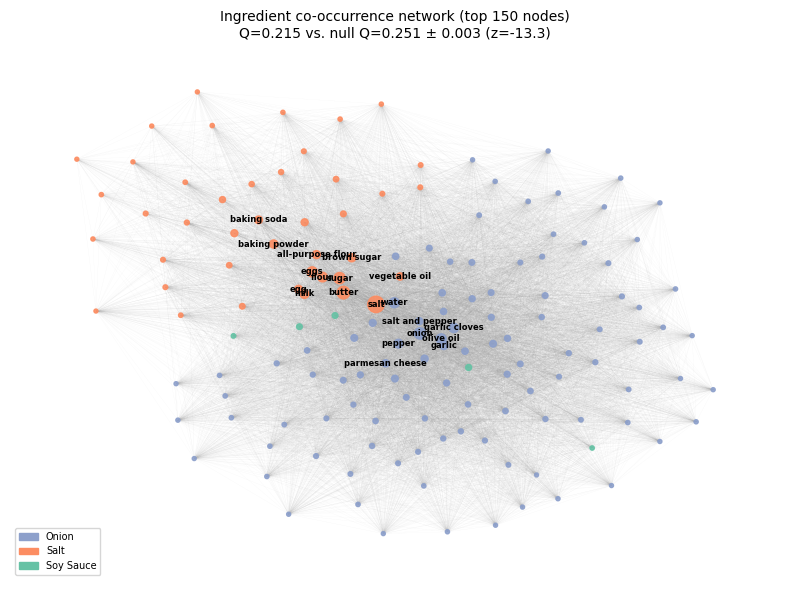

Saved fig1_network.pdf


In [23]:
# --- FIGURE 1: Ingredient co-occurrence network with communities ---
# Visualize a subgraph of the N most connected nodes for clarity
PLOT_N = 150  # top 150 nodes by degree for clarity
top_nodes = sorted(G.nodes(), key=lambda n: G.degree(n, weight='weight'), reverse=True)[:PLOT_N]
Gsub = G.subgraph(top_nodes).copy()

# Color by community
palette = plt.cm.Set2.colors + plt.cm.Set1.colors
unique_comms = list(set(partition.get(n, 0) for n in Gsub.nodes()))
comm_color = {c: palette[i % len(palette)] for i, c in enumerate(unique_comms)}
node_colors = [comm_color[partition.get(n, 0)] for n in Gsub.nodes()]
node_sizes = [5 + 0.0005 * weighted_degree.get(n, 0) for n in Gsub.nodes()]
edge_widths = [0.1 + 0.0001 * Gsub[u][v]['weight'] for u, v in Gsub.edges()]

pos = nx.spring_layout(Gsub, weight='weight', seed=42, k=0.5)

fig, ax = plt.subplots(figsize=(8, 6))
nx.draw_networkx_edges(Gsub, pos, alpha=0.15, width=edge_widths, edge_color='#999999', ax=ax)
nx.draw_networkx_nodes(Gsub, pos, node_color=node_colors, node_size=node_sizes, alpha=0.9, ax=ax)

# Label only top-20 nodes
top20 = sorted(Gsub.nodes(), key=lambda n: G.degree(n, weight='weight'), reverse=True)[:20]
labels = {n: n for n in top20}
nx.draw_networkx_labels(Gsub, pos, labels, font_size=6, font_weight='bold', ax=ax)

# Legend for communities
legend_patches = []
for comm_id in sorted(unique_comms, key=lambda c: community_sizes.get(c, 0), reverse=True)[:6]:
    label_str = auto_labels.get(comm_id, f'C{comm_id}')
    legend_patches.append(mpatches.Patch(color=comm_color[comm_id], label=label_str))
ax.legend(handles=legend_patches, loc='lower left', fontsize=7, framealpha=0.8)

ax.set_title(f'Ingredient co-occurrence network (top {PLOT_N} nodes)\n'
             f'Q={modularity_obs:.3f} vs. null Q={null_mean:.3f} ± {null_std:.3f} (z={z_score:.1f})',
             fontsize=10)
ax.axis('off')
plt.tight_layout()
plt.savefig('fig1_network.pdf', dpi=150, bbox_inches='tight')
plt.savefig('fig1_network.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig1_network.pdf')

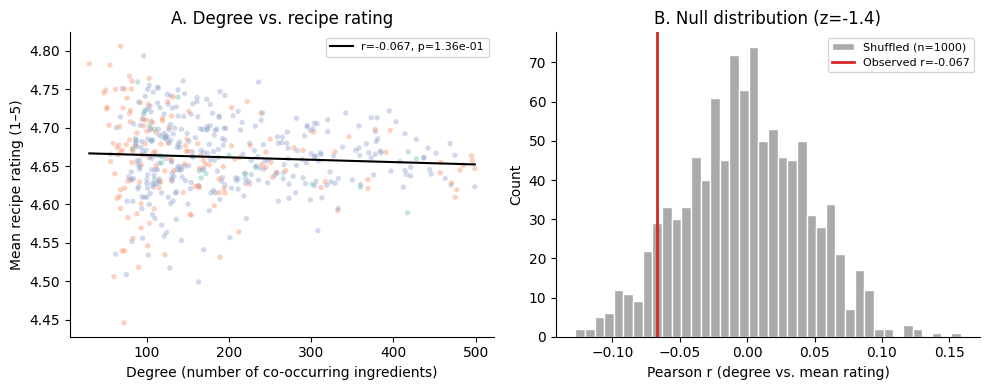

Saved fig2_centrality_rating.pdf


In [24]:
# --- FIGURE 2: Degree centrality vs. mean recipe rating + null ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Panel A: scatter degree vs. rating
ax = axes[0]
comm_ids_plot = ingr_df['community'].values
colors_plot = [comm_color.get(c, 'grey') for c in comm_ids_plot]
ax.scatter(ingr_df['degree'], ingr_df['mean_rating'], alpha=0.4, s=15,
           c=colors_plot, edgecolors='none')

# Regression line
x = ingr_df['degree'].values
y = ingr_df['mean_rating'].values
m, b = np.polyfit(x, y, 1)
xline = np.linspace(x.min(), x.max(), 100)
ax.plot(xline, m * xline + b, 'k-', lw=1.5, label=f'r={r_deg:.3f}, p={p_deg:.2e}')
ax.set_xlabel('Degree (number of co-occurring ingredients)')
ax.set_ylabel('Mean recipe rating (1–5)')
ax.set_title('A. Degree vs. recipe rating')
ax.legend(fontsize=8)

# Panel B: null distribution for r
ax = axes[1]
ax.hist(null_rs, bins=40, color='#aaaaaa', edgecolor='white', label='Shuffled (n=1000)')
ax.axvline(r_deg, color='#d62728', lw=2, label=f'Observed r={r_deg:.3f}')
ax.set_xlabel('Pearson r (degree vs. mean rating)')
ax.set_ylabel('Count')
ax.set_title(f'B. Null distribution (z={z_rating:.1f})')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('fig2_centrality_rating.pdf', dpi=150, bbox_inches='tight')
plt.savefig('fig2_centrality_rating.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig2_centrality_rating.pdf')

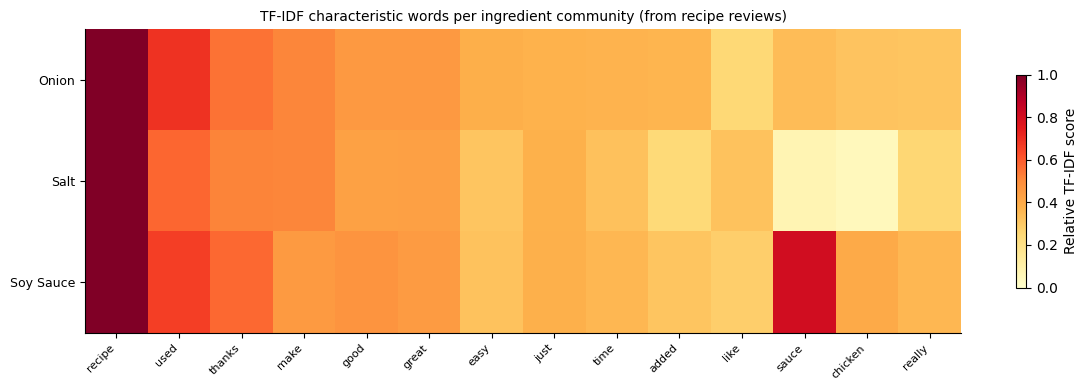

Saved fig3_tfidf.pdf


In [25]:
# --- FIGURE 3: TF-IDF heatmap of top words per community ---
all_top_words = []
for comm_id in FOCUS_COMMUNITIES:
    words = [w for w, _ in community_top_words.get(comm_id, [])[:10]]
    all_top_words.extend(words)

seen = set()
unique_top_words = []
for w in all_top_words:
    if w not in seen:
        seen.add(w)
        unique_top_words.append(w)
unique_top_words = unique_top_words[:30]

word_to_idx = {w: vectorizer.vocabulary_.get(w, None) for w in unique_top_words}
valid_words = [w for w in unique_top_words if word_to_idx[w] is not None]

heat_matrix = np.zeros((len(FOCUS_COMMUNITIES), len(valid_words)))
for i, comm_id in enumerate(FOCUS_COMMUNITIES):
    comm_idx = corpus_comm_ids.index(comm_id)
    row = tfidf_matrix[comm_idx]      # already dense — no .toarray() needed
    for j, word in enumerate(valid_words):
        idx = word_to_idx[word]
        if idx is not None:
            heat_matrix[i, j] = row[idx]

heat_norm = heat_matrix / (heat_matrix.max(axis=1, keepdims=True) + 1e-9)

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(heat_norm, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(len(valid_words)))
ax.set_xticklabels(valid_words, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(FOCUS_COMMUNITIES)))
ax.set_yticklabels([auto_labels.get(c, str(c)) for c in FOCUS_COMMUNITIES], fontsize=9)
ax.set_title('TF-IDF characteristic words per ingredient community (from recipe reviews)', fontsize=10)
plt.colorbar(im, ax=ax, shrink=0.7, label='Relative TF-IDF score')
plt.tight_layout()
plt.savefig('fig3_tfidf.pdf', dpi=150, bbox_inches='tight')
plt.savefig('fig3_tfidf.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig3_tfidf.pdf')

## 9. Summary statistics for the paper

In [26]:
print('=== PAPER STATISTICS ===')
print(f'Dataset: {len(recipes):,} recipes, {len(interactions):,} reviews (after filtering)')
print(f'Ingredient network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')
print(f'Network density: {nx.density(G):.4f}')
print(f'Largest connected component: {len(lcc)} / {TOP_K} nodes')
print(f'Communities (Louvain): {n_communities}, Q={modularity_obs:.4f}')
print(f'Null Q: {null_mean:.4f} ± {null_std:.4f}, z={z_score:.1f}')
print(f'Degree–rating correlation: r={r_deg:.3f}, p={p_deg:.2e}')
print(f'Null r: {null_r_mean:.4f} ± {null_r_std:.4f}, z={z_rating:.1f}')
print(f'Betweenness–rating correlation: r={r_bet:.3f}, p={p_bet:.2e}')
print(f'VADER validation (vs. star ratings): kappa={kappa:.3f}')

=== PAPER STATISTICS ===
Dataset: 87,313 recipes, 1,071,520 reviews (after filtering)
Ingredient network: 500 nodes, 47331 edges
Network density: 0.3794
Largest connected component: 500 / 500 nodes
Communities (Louvain): 3, Q=0.2149
Null Q: 0.2512 ± 0.0027, z=-13.3
Degree–rating correlation: r=-0.067, p=1.36e-01
Null r: -0.0016 ± 0.0459, z=-1.4
Betweenness–rating correlation: r=0.016, p=7.24e-01
VADER validation (vs. star ratings): kappa=0.412


In [27]:
# Sentiment by community (for paper)
print('\n=== SENTIMENT BY COMMUNITY ===')
all_comm_sentiments = {}
for comm_id in FOCUS_COMMUNITIES:
    comm_revs = interactions_filtered[interactions_filtered['community'] == comm_id]['review'].dropna()
    sample = comm_revs.sample(min(500, len(comm_revs)), random_state=42)
    scores = [analyzer.polarity_scores(str(r))['compound'] for r in sample]
    all_comm_sentiments[comm_id] = scores
    label = auto_labels.get(comm_id, str(comm_id))
    print(f'  Comm {comm_id} [{label}]: mean={np.mean(scores):.3f} ± {np.std(scores):.3f}')

# ANOVA across communities
f_stat, p_anova = stats.f_oneway(*all_comm_sentiments.values())
print(f'  ANOVA F={f_stat:.2f}, p={p_anova:.3e}')


=== SENTIMENT BY COMMUNITY ===
  Comm 2 [Onion]: mean=0.772 ± 0.280
  Comm 1 [Salt]: mean=0.791 ± 0.302
  Comm 0 [Soy Sauce]: mean=0.772 ± 0.297
  ANOVA F=0.69, p=5.041e-01


In [28]:
# Top/bottom ingredients by mean rating (for discussion)
top_rated = ingr_df.nlargest(10, 'mean_rating')[['ingredient', 'mean_rating', 'degree', 'n_recipes']]
bot_rated = ingr_df.nsmallest(10, 'mean_rating')[['ingredient', 'mean_rating', 'degree', 'n_recipes']]
print('Top 10 ingredients by mean rating:')
print(top_rated.to_string(index=False))
print('\nBottom 10 ingredients by mean rating:')
print(bot_rated.to_string(index=False))

Top 10 ingredients by mean rating:
        ingredient  mean_rating  degree  n_recipes
 vanilla ice cream     4.805884      68        337
       goat cheese     4.793270      96        232
   cranberry juice     4.782889      30        217
         cool whip     4.781189      55        454
        strawberry     4.766760      79        336
      strawberries     4.763923     103        472
   romaine lettuce     4.760445     144        382
fresh strawberries     4.760409      82        380
      whole cloves     4.759354      89        234
       feta cheese     4.759196     236       1095

Bottom 10 ingredients by mean rating:
            ingredient  mean_rating  degree  n_recipes
unsweetened applesauce     4.446006      72        246
cream of mushroom soup     4.499229     163        948
      splenda granular     4.505958      60        230
        onion soup mix     4.508897      75        263
        elbow macaroni     4.517496     128        442
            applesauce     4.518310

## 10. Additional check: degree distribution (for Methods section)

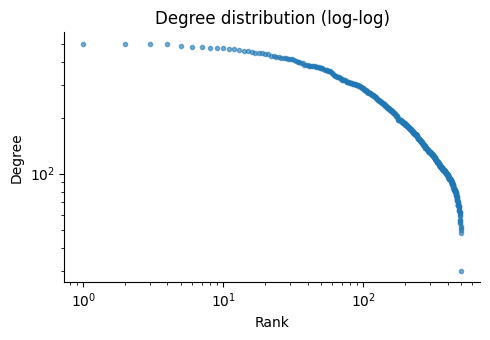

In [29]:
fig, ax = plt.subplots(figsize=(5, 3.5))
deg_seq = sorted(degrees, reverse=True)
ax.loglog(range(1, len(deg_seq)+1), deg_seq, 'o', ms=3, alpha=0.6, color='#1f77b4')
ax.set_xlabel('Rank')
ax.set_ylabel('Degree')
ax.set_title('Degree distribution (log-log)')
plt.tight_layout()
plt.savefig('fig_supp_degree.pdf', dpi=150, bbox_inches='tight')
plt.savefig('fig_supp_degree.png', dpi=150, bbox_inches='tight')
plt.show()